In [1]:
%pip install Pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

Looking in indexes: https://download.pytorch.org/whl/cu121
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models, datasets
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader, Subset, random_split
from torch.optim.lr_scheduler import OneCycleLR


In [14]:
#Flower path
flower_path = "datasets/flowers"

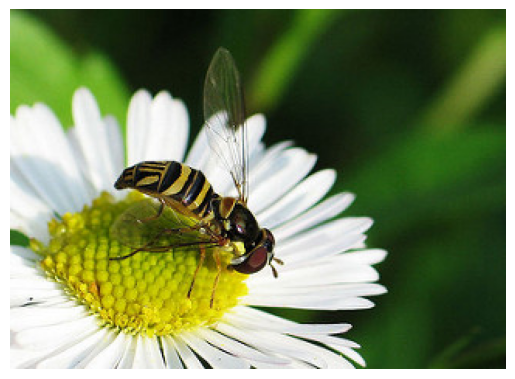

(320, 232)

In [15]:
#Test image loading

image_path = os.path.join(flower_path, "daisy/5547758_eea9edfd54_n.jpg")
img = Image.open(image_path)

plt.imshow(img)
plt.axis("off")
plt.show()

img.size

In [16]:
import sys
import torch

print(sys.executable)
print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.is_available())

d:\Work\ExcelAI\.venv\Scripts\python.exe
2.12.0+cpu
None
False


In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [18]:
#Flower path
flower_path = "datasets/flowers"

In [19]:
train_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomRotation(degrees=30),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

val_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

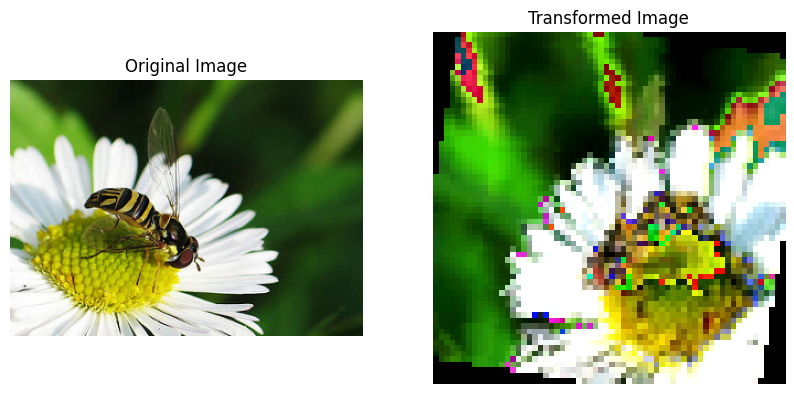

In [20]:
transformed_img = train_transforms(img)
transformed_img = transforms.ToPILImage()(transformed_img)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(transformed_img)
axes[1].set_title("Transformed Image")
axes[1].axis("off")

plt.show()

In [21]:
full_dataset = datasets.ImageFolder(root=flower_path, transform=None)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

class TransformDataset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, label = self.subset[idx]
        return self.transform(img), label
    
train_dataset = TransformDataset(train_dataset, train_transforms)
val_dataset = TransformDataset(val_dataset, val_transforms)


In [22]:
#If we have them split alr by train and val folders, we can use ImageFolder directly with transforms

train_dataset = datasets.ImageFolder(root=os.path.join(flower_path, "train"), transform=train_transforms)
val_dataset = datasets.ImageFolder(root=os.path.join(flower_path, "val"), transform=val_transforms)

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'datasets/flowers\\train'

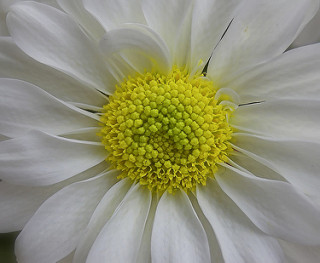

In [23]:
#Before transforms
img, label = full_dataset[0]
img

In [24]:
#After transforms
transformed_img, label = train_dataset[0]
transformed_img

tensor([[[-1., -1., -1.,  ..., -1., -1., -1.],
         [-1., -1., -1.,  ..., -1., -1., -1.],
         [-1., -1., -1.,  ..., -1., -1., -1.],
         ...,
         [-1., -1., -1.,  ..., -1., -1., -1.],
         [-1., -1., -1.,  ..., -1., -1., -1.],
         [-1., -1., -1.,  ..., -1., -1., -1.]],

        [[-1., -1., -1.,  ..., -1., -1., -1.],
         [-1., -1., -1.,  ..., -1., -1., -1.],
         [-1., -1., -1.,  ..., -1., -1., -1.],
         ...,
         [-1., -1., -1.,  ..., -1., -1., -1.],
         [-1., -1., -1.,  ..., -1., -1., -1.],
         [-1., -1., -1.,  ..., -1., -1., -1.]],

        [[-1., -1., -1.,  ..., -1., -1., -1.],
         [-1., -1., -1.,  ..., -1., -1., -1.],
         [-1., -1., -1.,  ..., -1., -1., -1.],
         ...,
         [-1., -1., -1.,  ..., -1., -1., -1.],
         [-1., -1., -1.,  ..., -1., -1., -1.],
         [-1., -1., -1.,  ..., -1., -1., -1.]]])

In [25]:
from collections import Counter
#label_counts = Counter(labels)
#print(label_counts)

DataLoad

In [26]:
BATCH_SIZE = 64
NUM_WORKERS = 4
PIN_MEMORY = True if torch.cuda.is_available() else False

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

print("Classes:", full_dataset.classes)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Training samples: 3453
Validation samples: 864


In [ ]:
# Get one batch of data
images, labels = next(iter(train_loader))
print("Batch of images shape:", images.shape)
print("Batch of labels:", labels)

Model

In [27]:
class ConvolutionalNN(nn.Module):
    def __init__(self, num_classes=5):
        super(ConvolutionalNN, self).__init__()

        # CRBP - Convolution, ReLU, BatchNorm, Pooling

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.fc_layers = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes * 2),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(num_classes * 2, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)

        return x

In [28]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [29]:
count_parameters(ConvolutionalNN())

129345

In [ ]:
#Test
model = ConvolutionalNN()
images, labels = next(iter(train_loader))
model(images)

In [30]:
HYPERPARAMETERS = dict(
    EPOCHS=50,
    BATCH_SIZE=BATCH_SIZE,
    LR=1e-3,
    MAX_LR=1e-2,
)

#MOC(S)

#Model

model = ConvolutionalNN().to(device)

#Optimizer

optimizer = torch.optim.Adam(model.parameters(), lr=HYPERPARAMETERS["LR"])

#Loss function -> criterion

criterion = nn.CrossEntropyLoss()

#Optional -> scheduler

scheduler = OneCycleLR(
    optimizer,
    max_lr=HYPERPARAMETERS["MAX_LR"],
    steps_per_epoch=len(train_loader),
    epochs=HYPERPARAMETERS["EPOCHS"]
)

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [ ]:
def train_step(model, train_loader, criterion, optimizer, scheduler = None):
    model.train()
    running_train_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        #Zero the gradients
        optimizer.zero_grad()

        #Forward pass
        outputs = model(images)

        #Calculate loss
        loss = criterion(outputs, labels)

        #Backward pass
        loss.backward()

        #Update weights
        optimizer.step()

        #Update scheduler
        if scheduler:
            scheduler.step()

        #Accumulate loss
        running_train_loss += loss.item()

        #Get predictions
        _, preds = torch.max(outputs, 1)

        #Accumulate predictions and labels for metrics
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    metrics = dict(
        loss = running_train_loss / len(train_loader),
        accuracy = accuracy_score(all_labels, all_preds),
        precision = precision_score(all_labels, all_preds, average="weighted"),
        recall = recall_score(all_labels, all_preds, average="weighted"),
        f1 = f1_score(all_labels, all_preds, average="weighted")
    )

    return metrics

In [ ]:
def validate_step(model, val_loader, criterion):
    model.eval()
    running_val_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            #Forward pass
            outputs = model(images)

            #Calculate loss
            loss = criterion(outputs, labels)

            #Accumulate loss
            running_val_loss += loss.item()

            #Get predictions
            _, preds = torch.max(outputs, 1)

            #Store predictions and labels for metrics
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    metrics = dict(
        loss = running_val_loss / len(val_loader),
        accuracy = accuracy_score(all_labels, all_preds),
        precision = precision_score(all_labels, all_preds, average="weighted"),
        recall = recall_score(all_labels, all_preds, average="weighted"),
        f1 = f1_score(all_labels, all_preds, average="weighted")
    )

    return metrics

In [32]:
import copy

In [33]:
HYPERPARAMETERS['PATIENCE'] = 15
best_value = 0
epochs_no_improve = 0
best_model_wts = None
metrics = []

In [ ]:
for epoch in range(HYPERPARAMETERS["EPOCHS"]):
    #Train step
    train_metrics = train_step(model, train_loader, criterion, optimizer, scheduler)

    #Validation step
    val_metrics = validate_step(model, val_loader, criterion)

    #Print metrics
    print(f"Epoch {epoch+1}/{HYPERPARAMETERS['EPOCHS']}")
    print(f"Train Loss: {train_metrics['loss']:.4f} | Train Acc: {train_metrics['accuracy']:.4f} | Train Prec: {train_metrics['precision']:.4f} | Train Rec: {train_metrics['recall']:.4f} | Train F1: {train_metrics['f1']:.4f}")
    print(f"Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f} | Val Prec: {val_metrics['precision']:.4f} | Val Rec: {val_metrics['recall']:.4f} | Val F1: {val_metrics['f1']:.4f}")
    print("-" * 50)

    metrics.append({
        'train': train_metrics,
        'val': val_metrics
    })

    #Early stopping
    if val_metrics['f1'] > best_value:
        best_value = val_metrics['f1']
        epochs_no_improve = 0
        best_model_wts = copy.deepcopy(model.state_dict())
    else:
        epochs_no_improve += 1

    if epochs_no_improve >= HYPERPARAMETERS['PATIENCE']:
        print(f"Early stopping at epoch {epoch+1}")
        break

In [ ]:
model.load_state_dict(best_model_wts)

In [ ]:
torch.save(model.state_dict(), "best_flower_model.pth")
model.load_state_dict(torch.load("best_flower_model.pth"))

In [ ]:
final_metrics = validate_step(model, val_loader, criterion)
print(f"Final Val Loss: {final_metrics['loss']:.4f} | Final Val Acc: {final_metrics['accuracy']:.4f} | Final Val Prec: {final_metrics['precision']:.4f} | Final Val Rec: {final_metrics['recall']:.4f} | Final Val F1: {final_metrics['f1']:.4f}")

In [ ]:
train_losses = [epoch_metrics['train']['loss'] for epoch_metrics in metrics]
val_losses = [epoch_metrics['val']['loss'] for epoch_metrics in metrics]
train_accuracies = [epoch_metrics['train']['accuracy'] for epoch_metrics in metrics]
val_accuracies = [epoch_metrics['val']['accuracy'] for epoch_metrics in metrics]
train_f1 = [epoch_metrics['train']['f1'] for epoch_metrics in metrics]
val_f1 = [epoch_metrics['val']['f1'] for epoch_metrics in metrics]

In [ ]:
def plot_metrics(train_metrics, val_metrics, epochs, metrics):
    plt.figure(figsize=(12, 5))
    plt.plot(epochs, train_metrics, label='Train ' + metrics, color='blue', marker='o')
    plt.plot(epochs, val_metrics, label='Val ' + metrics, color='red', marker='x')
    plt.xlabel('Epoch')
    plt.ylabel(metrics)
    plt.title('Training and Validation ' + metrics)
    plt.legend()
    plt.show()

In [ ]:
epochs_trained = len(metrics)


In [ ]:
plot_metrics(train_losses, val_losses, list(range(1, epochs_trained + 1)), "Loss")

In [ ]:
#Pizza path
pizza_path = "datasets/pizza_not_pizza"


In [ ]:
#Test image loading

image_path = os.path.join(pizza_path, "pizza/2965.jpg")
img = Image.open(image_path)
plt.imshow(img)
plt.axis("off")

In [ ]:
img.size

In [ ]:
print("Pizzas: ", len(os.listdir(os.path.join(pizza_path, "pizza"))))
print("Not Pizzas: ", len(os.listdir(os.path.join(pizza_path, "not_pizza"))))

In [ ]:
train_transforms_pizza = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomRotation(degrees=30),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])


val_transforms_pizza = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])


In [ ]:
transformed_img = train_transforms_pizza(img)
transformed_img = transforms.ToPILImage()(transformed_img)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img)
axes[0].set_title("Original Image")
axes[0].axis("off")
axes[1].imshow(transformed_img)
axes[1].set_title("Transformed Image")
axes[1].axis("off")

plt.show()

Dataset

In [ ]:
full_dataset_pizza = datasets.ImageFolder(root=pizza_path, transform=None)

train_size = int(0.8 * len(full_dataset_pizza))
val_size = len(full_dataset_pizza) - train_size
train_dataset_pizza, val_dataset_pizza = random_split(full_dataset_pizza, [train_size, val_size])

class TransformDatasetPizza(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, label = self.subset[idx]
        return self.transform(img), label
    
train_dataset_pizza = TransformDatasetPizza(train_dataset_pizza, train_transforms_pizza)
val_dataset_pizza = TransformDatasetPizza(val_dataset_pizza, val_transforms_pizza)

In [ ]:
num_classes_pizza = len(full_dataset_pizza.classes)
print("Classes:", full_dataset_pizza.classes, "Num classes:", num_classes_pizza)

In [ ]:
image, label = full_dataset_pizza[0]
image

In [ ]:
image, label = train_dataset_pizza[0]
image

In [ ]:
labels = full_dataset_pizza.targets
Counter(labels)

In [ ]:
BATCH_SIZE

In [ ]:
train_loader_pizza = DataLoader(train_dataset_pizza, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader_pizza = DataLoader(val_dataset_pizza, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

print("Classes:", full_dataset_pizza.classes)
print("Training samples:", len(train_dataset_pizza))
print("Validation samples:", len(val_dataset_pizza))

In [ ]:
images, labels = next(iter(train_loader_pizza))

print("Batch of images shape:", images.shape)
print("Batch of labels:", labels)

In [ ]:
class ConvolutionalNNPizza(nn.Module):
    def __init__(self, num_classes=2):
        super(ConvolutionalNNPizza, self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.fc_layers = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.AdaptiveAvgPool1d(512),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 32),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)

        return x

In [ ]:
def count_parameters(ConvolutionalNNPizza):
    return sum(p.numel() for p in ConvolutionalNNPizza.parameters() if p.requires_grad)

In [ ]:
count_parameters(ConvolutionalNNPizza())

In [ ]:
model = ConvolutionalNNPizza()
images, labels = next(iter(train_loader_pizza))
model(images)

In [ ]:
HYPERPARAMETERS

In [34]:
HYPERPARAMETERS["EPOCHS"] = 20

In [ ]:
HYPERPARAMETERS

In [ ]:
#MOC(S = Model, Optimizer, Criterion, Scheduler)

#Model

modelPizza = ConvolutionalNNPizza().to(device)

#Optimizer

optimizerPizza = torch.optim.SGD(modelPizza.parameters(), lr=HYPERPARAMETERS["LR"])

#Criterion

criterionPizza = nn.CrossEntropyLoss()

#Scheduler

schedulerPizza = OneCycleLR(
    optimizerPizza,
    max_lr=HYPERPARAMETERS["MAX_LR"],
    steps_per_epoch=len(train_loader_pizza),
    epochs=HYPERPARAMETERS["EPOCHS"]
)

In [ ]:
def train_step_pizza(model, train_loader, criterion, optimizer, scheduler = None):
    model.train()
    running_train_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        #Zero the gradients
        optimizer.zero_grad()

        #Forward pass
        outputs = model(images)

        #Calculate loss
        loss = criterion(outputs, labels)

        #Backward pass
        loss.backward()

        #Update weights
        optimizer.step()

        #Update scheduler
        if scheduler:
            scheduler.step()

        #Accumulate loss
        running_train_loss += loss.item()

        #Get predictions
        _, preds = torch.max(outputs, 1)

        #Accumulate predictions and labels for metrics
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    metrics = dict(
        loss = running_train_loss / len(train_loader),
        accuracy = accuracy_score(all_labels, all_preds),
        precision = precision_score(all_labels, all_preds, average="weighted"),
        recall = recall_score(all_labels, all_preds, average="weighted"),
        f1 = f1_score(all_labels, all_preds, average="weighted")
    )

    return metrics

In [ ]:
def validate_step_pizza(model, val_loader, criterion):
    model.eval()
    running_val_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            #Forward pass
            outputs = model(images)

            #Calculate loss
            loss = criterion(outputs, labels)

            #Accumulate loss
            running_val_loss += loss.item()

            #Get predictions
            _, preds = torch.max(outputs, 1)

            #Store predictions and labels for metrics
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    metrics = dict(
        loss = running_val_loss / len(val_loader),
        accuracy = accuracy_score(all_labels, all_preds),
        precision = precision_score(all_labels, all_preds, average="weighted"),
        recall = recall_score(all_labels, all_preds, average="weighted"),
        f1 = f1_score(all_labels, all_preds, average="weighted")
    )

    return metrics

In [ ]:
metrics_pizza = []
best_value_pizza = 0
epochs_no_improve_pizza = 0
best_model_wts_pizza = None

for epoch in range(HYPERPARAMETERS["EPOCHS"]):
    #Train step
    train_metrics_pizza = train_step_pizza(modelPizza, train_loader_pizza, criterionPizza, optimizerPizza, schedulerPizza)

    #Validation step
    val_metrics_pizza = validate_step_pizza(modelPizza, val_loader_pizza, criterionPizza)

    #Print metrics

    print(f"Epoch {epoch+1}/{HYPERPARAMETERS['EPOCHS']}")
    print(f"Train :", train_metrics_pizza)
    print(f"Val :", val_metrics_pizza)
    print("-" * 50)

    metrics_pizza.append({
        'train': train_metrics_pizza,
        'val': val_metrics_pizza
    })

    if val_metrics_pizza['f1'] > best_value_pizza:
        best_value_pizza = val_metrics_pizza['f1']
        epochs_no_improve_pizza = 0
        best_model_wts_pizza = copy.deepcopy(modelPizza.state_dict())
    else:
        epochs_no_improve_pizza += 1
    
    if epochs_no_improve_pizza >= HYPERPARAMETERS['PATIENCE']:
        print(f"Early stopping at epoch {epoch+1}")
        break

In [ ]:
modelPizza.load_state_dict(best_model_wts_pizza)

In [ ]:
#Plot accuracy
train_accuracies_pizza = [epoch_metrics['train']['accuracy'] for epoch_metrics in metrics_pizza]
val_accuracies_pizza = [epoch_metrics['val']['accuracy'] for epoch_metrics in metrics_pizza]
epochs_trained_pizza = len(metrics_pizza)
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs_trained_pizza + 1), train_accuracies_pizza, label='Train Accuracy', color='blue', marker='o')
plt.plot(range(1, epochs_trained_pizza + 1), val_accuracies_pizza, label='Val Accuracy', color='red', marker='x')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

In [35]:
#CatDog path
catdog_path = "datasets/PetImages"

(np.float64(-0.5), np.float64(499.5), np.float64(374.5), np.float64(-0.5))

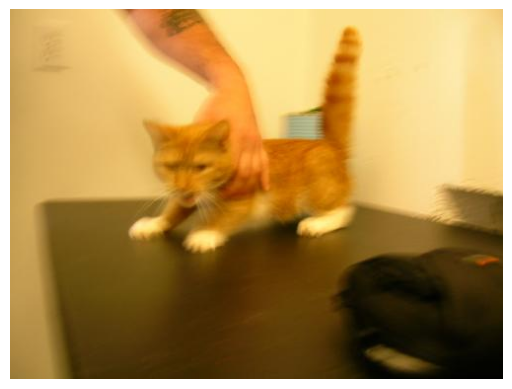

In [36]:
#Image loading test

image_path = os.path.join(catdog_path, "cat/0.jpg")
img = Image.open(image_path)
plt.imshow(img)
plt.axis("off")

Transformations

In [37]:
train_transforms_catdog = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomRotation(degrees=30),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

val_transforms_catdog = transforms.Compose([ 
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

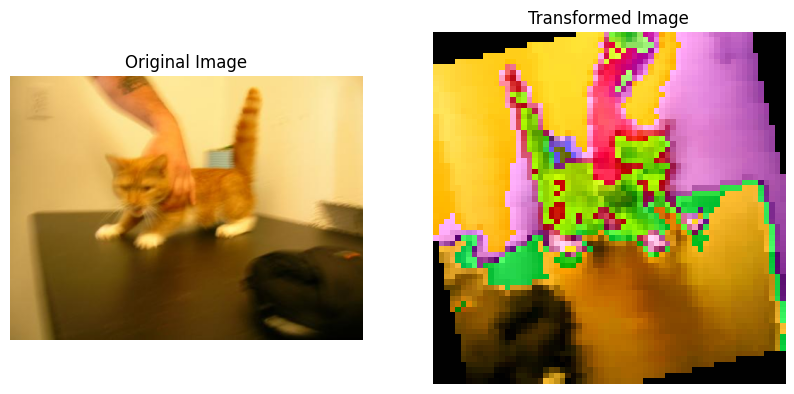

In [38]:
transformed_img = train_transforms_catdog(img)
transformed_img = transforms.ToPILImage()(transformed_img)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img)
axes[0].set_title("Original Image")
axes[0].axis("off")
axes[1].imshow(transformed_img)
axes[1].set_title("Transformed Image")
axes[1].axis("off")
plt.show()

In [39]:
def is_valid_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

full_dataset_catdog = datasets.ImageFolder(root=catdog_path, transform=None, is_valid_file=is_valid_image)
print("Valid images:", len(full_dataset_catdog))


train_size = int(0.8 * len(full_dataset_catdog))
val_size = len(full_dataset_catdog) - train_size
train_dataset_catdog, val_dataset_catdog = random_split(full_dataset_catdog, [train_size, val_size])

train_dataset_catdog = TransformDataset(train_dataset_catdog, train_transforms_catdog)
val_dataset_catdog = TransformDataset(val_dataset_catdog, val_transforms_catdog)

Valid images: 24998


d:\Work\ExcelAI\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Loader

In [40]:
train_loader_catdog = DataLoader(train_dataset_catdog, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader_catdog = DataLoader(val_dataset_catdog, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

#Distribution check
print("Classes:", full_dataset_catdog.classes)
print("Training samples:", len(train_dataset_catdog))
print("Validation samples:", len(val_dataset_catdog))

Classes: ['Cat', 'Dog']
Training samples: 19998
Validation samples: 5000


In [41]:
class ConvolutionalNNCatDog(nn.Module):
    def __init__(self, num_classes=2):
        super(ConvolutionalNNCatDog, self).__init__()

        #CRBP - Convolution, ReLU, BatchNorm, Pooling
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.fc_layers = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.AdaptiveAvgPool1d(512),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 32),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)

        return x

In [42]:
def count_parameters(ConvolutionalNNCatDog):
    return sum(p.numel() for p in ConvolutionalNNCatDog.parameters() if p.requires_grad)

In [43]:
count_parameters(ConvolutionalNNCatDog())

233314

In [44]:
#MOC(S) - Model, Optimizer, Criterion, Scheduler

#Model
modelCatDog = ConvolutionalNNCatDog().to(device)

#Optimizer
optimizerCatDog = torch.optim.Adam(modelCatDog.parameters(), lr=HYPERPARAMETERS["LR"])

#Criterion
criterionCatDog = nn.CrossEntropyLoss()

#Scheduler - OPTIONAL
schedulerCatDog = OneCycleLR(
    optimizerCatDog,
    max_lr=HYPERPARAMETERS["MAX_LR"],
    steps_per_epoch=len(train_loader_catdog),
    epochs=HYPERPARAMETERS["EPOCHS"]
)

In [45]:
def train_step_catdog(model, train_loader, criterion, optimizer, scheduler = None):
    model.train()
    running_train_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        #Zero the gradients
        optimizer.zero_grad()

        #Forward pass
        outputs = model(images)

        #Calculate loss
        loss = criterion(outputs, labels)

        #Backward pass
        loss.backward()

        #Update weights
        optimizer.step()

        #Update scheduler
        if scheduler:
            scheduler.step()

        #Accumulate loss
        running_train_loss += loss.item()

        #Get predictions
        _, preds = torch.max(outputs, 1)

        #Accumulate predictions and labels for metrics
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    metrics = dict(
        loss = running_train_loss / len(train_loader),
        accuracy = accuracy_score(all_labels, all_preds),
        precision = precision_score(all_labels, all_preds, average="weighted"),
        recall = recall_score(all_labels, all_preds, average="weighted"),
        f1 = f1_score(all_labels, all_preds, average="weighted")
    )

    return metrics

In [46]:
def val_step_catdog(model, val_loader, criterion):
    model.eval()
    running_val_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            #Forward pass
            outputs = model(images)

            #Calculate loss
            loss = criterion(outputs, labels)

            #Accumulate loss
            running_val_loss += loss.item()

            #Get predictions
            _, preds = torch.max(outputs, 1)

            #Store predictions and labels for metrics
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    metrics = dict(
        loss = running_val_loss / len(val_loader),
        accuracy = accuracy_score(all_labels, all_preds),
        precision = precision_score(all_labels, all_preds, average="weighted"),
        recall = recall_score(all_labels, all_preds, average="weighted"),
        f1 = f1_score(all_labels, all_preds, average="weighted")
    )

    return metrics

In [ ]:
metrics_catdog = []
best_value_catdog = 0
epochs_no_improve_catdog = 0
best_model_wts_catdog = None

for epoch in range(HYPERPARAMETERS["EPOCHS"]):
    #Train step
    train_metrics_catdog = train_step_catdog(modelCatDog, train_loader_catdog, criterionCatDog, optimizerCatDog, schedulerCatDog)

    #Validation step
    val_metrics_catdog = val_step_catdog(modelCatDog, val_loader_catdog, criterionCatDog)

    #Print metrics
    print(f"Epoch {epoch+1}/{HYPERPARAMETERS['EPOCHS']}")
    print("Train :", train_metrics_catdog)
    print("Val :", val_metrics_catdog)
    print("-" * 50)

    metrics_catdog.append({
        'train': train_metrics_catdog,
        'val': val_metrics_catdog
    })

    #Early stopping

    if val_metrics_catdog['f1'] > best_value_catdog:
        best_value_catdog = val_metrics_catdog['f1']
        epochs_no_improve_catdog = 0
        best_model_wts_catdog = copy.deepcopy(modelCatDog.state_dict())
    else:
        epochs_no_improve_catdog += 1
    
    if epochs_no_improve_catdog >= HYPERPARAMETERS['PATIENCE']:
        print(f"Early stopping at epoch {epoch+1}")
        break


In [ ]:
modelCatDog.load_state_dict(best_model_wts_catdog)

In [ ]:
#Plot accuracy
train_accuracies_catdog = [epoch_metrics['train']['accuracy'] for epoch_metrics in metrics_catdog]
val_accuracies_catdog = [epoch_metrics['val']['accuracy'] for epoch_metrics in metrics_catdog]
epochs_trained_catdog = len(metrics_catdog)
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs_trained_catdog + 1), train_accuracies_catdog, label='Train Accuracy', color='blue', marker='o')
plt.plot(range(1, epochs_trained_catdog + 1), val_accuracies_catdog, label='Val Accuracy', color='red', marker='x')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()